# B3. purity 가 낮으면 왜 CN 이 흔들리나

**목표**
- purity 가 낮을 때 CN 이 흔들리는 이유를 네 가지로 나눠, 하나씩 그림과 시뮬레이션으로 확인합니다.
- 실제 PURPLE 결과에서 이 문제를 알아보는 방법을 정리합니다.

**이 노트북이 답하는 질문**: purity 가 낮을수록 왜 CN 이 흔들리나?

`[번호]` 는 맨 아래 **출처** 절의 번호입니다. 표와 그림의 숫자 가운데 출처 번호가 없는 것은 **이 노트북의 시뮬레이션 결과**입니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 공통 스타일 STYLE.md §3-1, 팔레트 Okabe-Ito(색의 뜻 고정)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Rectangle
import purple_mini as pm

from scipy.stats import norm

# ---- 공통 그림 스타일 (study_build/purple/_proto_pileup.py 에서 복사, STYLE.md §3-1) ----
# 색은 뜻이 고정: 종양 주황, 정상 하늘, allele A 파랑, allele B 빨강, read 회청, 핵심 메시지 자주, 정답·통과 초록.
# 그 밖의 비교(조건 둘, purity 여러 개)는 진한 회색 계열(GREYS)과 선 모양으로 구분하고 직접 라벨을 단다.
import logging
from matplotlib.patches import FancyBboxPatch

COL = dict(tumour="#E69F00", normal="#56B4E9", alleleA="#0072B2", alleleB="#D55E00",
           read="#8C9BAB", read_rev="#B3BFCC", highlight="#CC79A7", ok="#009E73",
           ink="#222222", muted="#6B7280", grid="#E5E7EB", shade="#FFF4E0")
GREYS = ["#111827", "#4B5563", "#8B95A3", "#BCC3CC"]      # 순서 있는 비교용(진한 것 = 첫째)
TUMOUR_LIGHT, NORMAL_LIGHT, BOX = "#FBE3B6", "#CDE8F8", "#F1F3F6"
NEUTRAL = "#E6E9EE"                                      # 종양과 상관없는 강조 띠·상자 (옅은 주황 shade 는 종양 구간에만)
LABEL_BOX = dict(fc="white", ec="none", alpha=0.85, pad=1.5)   # 선이나 점 위에 놓이는 글자 뒤 흰 상자


def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5,
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white",
    })


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}" if letter else title)


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """그림의 핵심 메시지 한 줄(자주색 굵게). 데이터 위에 겹치지 않는 빈 자리에 둔다."""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    ax.text(x, y, text, **kw)


def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)


apply_theme()


def flow(ax, nodes, edges, fs=9.5, W=2.9, H=1.0):
    for x, y, text, col in nodes.values():
        ax.add_patch(FancyBboxPatch((x - W / 2, y - H / 2), W, H, boxstyle="round,pad=0.04,rounding_size=0.18",
                                    fc=col, ec="#C4CAD3", lw=0.9, zorder=2))
        ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=COL["ink"], zorder=3)
    for a, b in edges:
        (x1, y1), (x2, y2) = nodes[a][:2], nodes[b][:2]
        ax.annotate("", xy=(x2 - W / 2, y2), xytext=(x1 + W / 2, y1), zorder=1,
                    arrowprops=dict(arrowstyle="-|>", lw=1.0, color=COL["muted"], shrinkA=2, shrinkB=2, mutation_scale=11))
    ax.set_axis_off()


def draw_concept_map():
    fig, ax = plt.subplots(figsize=(12.5, 5.0))
    ys = [3.9, 2.7, 1.5, 0.3]
    nodes = {"low": (1.6, 2.1, "Low purity\n(few tumour cells)", TUMOUR_LIGHT)}
    causes = ["1. one copy moves the\nratio by only p/2", "2. BAF squeezed\ntowards 0.5",
              "3. CN tolerance fixed,\nCN noise grows", "4. score landscape\nflattens"]
    effects = ["CN noise grows as 1/p", "major/minor split fails", "unsupported segments\n-> noise warning",
               "fit jumps to 'doubled'\nsolution (lower p, higher ploidy)"]
    for i, (c, e, y) in enumerate(zip(causes, effects, ys)):
        nodes[f"c{i}"] = (5.6, y, c, BOX)
        nodes[f"e{i}"] = (9.9, y, e, "white")
    flow(ax, nodes, [("low", f"c{i}") for i in range(4)] + [(f"c{i}", f"e{i}") for i in range(4)])
    ax.text(5.6, 4.55, "why", ha="center", fontsize=10.5, weight="semibold", color=COL["ink"])
    ax.text(9.9, 4.55, "what you see", ha="center", fontsize=10.5, weight="semibold", color=COL["ink"])
    ax.add_patch(FancyBboxPatch((11.55, 1.05), 1.75, 3.35, boxstyle="round,pad=0,rounding_size=0.15", fc="none",
                                ec=COL["muted"], lw=1.2, ls=(0, (4, 3)), zorder=0))
    note(ax, 12.42, 2.75, "causes 1-3:\neach segment\nwobbles", ha="center", va="center", color=COL["ink"], fontsize=9.5)
    note(ax, 12.42, 0.3, "cause 4:\nwhole map\nshifts", ha="center", va="center", color=COL["ink"], fontsize=9.5)
    callout(ax, 0.2, 5.0, "One root cause (few tumour cells), four ways the copy number wobbles", va="bottom")
    ax.set_xlim(0, 13.4); ax.set_ylim(-0.4, 5.4)
    plt.show()


def draw_ladder(sigma=0.04, purities=(0.8, 0.2)):
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0), sharey=True, gridspec_kw={"wspace": 0.06})
    r = np.linspace(0.4, 2.0, 600)
    for ax, letter, p in zip(axes, "AB", purities):
        nf = pm.norm_factor(p, 2.0)
        for k, col in zip([1, 2, 3, 4], GREYS[::-1]):
            mu = pm.ratio_from_cn(k, p, nf)
            y = norm.pdf(r, mu, sigma * mu)
            ax.fill_between(r, y, color=col, alpha=0.35, lw=0)
            ax.plot(r, y, color=col, lw=1.4)
            ax.text(mu, y.max() * 1.03, f"CN {k}", ha="center", va="bottom", fontsize=9.5, color=GREYS[1] if col == GREYS[3] else col)
        panel(ax, letter, f"purity {p}: one copy = {nf * p / 2:.2f} ratio, noise SD ~{sigma:.0%}")
        ax.set_xlabel("depth ratio of a 100 kb bin"); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    top = axes[1].get_ylim()[1]
    axes[1].set_ylim(0, top * 1.12)
    callout(axes[1], 1.95, top * 1.08, "neighbouring copy numbers now overlap", ha="right", va="top")
    plt.show()


def draw_baf_overlap(depth=60, purities=(0.8, 0.15), n=6000, seed=0):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0), sharey=True, gridspec_kw={"wspace": 0.06})
    bins = np.linspace(0.5, 1, 51)
    thr = pm.ambiguous_baf(depth)
    for ax, letter, p in zip(axes, "AB", purities):
        for (M, m), col, name in [((1, 1), "#BCC3CC", "balanced (1,1)"), ((2, 1), GREYS[0], "gain (2,1)")]:
            b = pm.expected_baf(p, M, m)
            d = np.maximum(rng.poisson(depth, n), 1)
            raw = rng.binomial(d, np.where(rng.random(n) < 0.5, b, 1 - b)) / d
            if (M, m) == (1, 1):
                ax.hist(0.5 + np.abs(raw - 0.5), bins=bins, color=col, lw=0)
            else:
                ax.hist(0.5 + np.abs(raw - 0.5), bins=bins, histtype="step", color=col, lw=1.8)
            ax.axvline(b, color=col, lw=1.0)
        ax.axvline(thr, color=COL["ink"], ls=(0, (4, 2)), lw=1.3)
        top = ax.get_ylim()[1]
        note(ax, thr + 0.008, top * 0.97, f"ambiguity\nthreshold {thr:.3f}", va="top", color=COL["ink"], bbox=LABEL_BOX)
        note(ax, 0.99, top * 0.62, f"filled bars: balanced (1,1)\ndark outline: gain (2,1), expected {pm.expected_baf(p, 2, 1):.3f}",
             ha="right", va="top", color=COL["ink"], fontsize=9.5)
        panel(ax, letter, f"purity {p}, depth {depth}"); ax.set_xlabel("folded BAF of single SNP sites"); ygrid(ax)
    axes[0].set_ylabel("number of SNP sites")
    callout(axes[1], 0.99, axes[1].get_ylim()[1] * 0.35, "the two piles now overlap", ha="right", va="top")
    plt.show()


def draw_pcf_and_tolerance(profile, wave=0.05, windows=1000):
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.22})
    one = profile[profile.chromosome == "1"]
    bins, _ = pm.simulate(one, 0.4, depth=60, sys_sd=0.04, seed=2)
    y = np.log2(bins.ratio.to_numpy())
    cuts = pm.pcf(y)
    ax = axes[0]
    ax.plot(np.arange(len(y)) / 10, y, ".", ms=1.6, color=COL["read"], rasterized=True)
    edges = [0, *cuts, len(y)]
    for s, e in zip(edges[:-1], edges[1:]):
        ax.plot([s / 10, e / 10], [y[s:e].mean()] * 2, color=COL["ink"], lw=1.6)
    for b in one.start_bin.iloc[1:]:
        ax.axvline(b / 10, color=COL["muted"], lw=0.9, ls=":")
    ax.set_xlabel("chr1 position (Mb)"); ax.set_ylabel("log2 depth ratio"); ygrid(ax)
    panel(ax, "A", "PCF cuts at real changes (dotted) and also at noise waves")
    callout(ax, len(y) / 10, ax.get_ylim()[1], f"{len(cuts)} cuts vs {len(one) - 1} real changes", ha="right", va="top", bbox=LABEL_BOX)
    ax = axes[1]
    pur = np.linspace(0.08, 0.9, 200)
    gap = 2 * wave / pur                      # 같은 5% 물결이 CN 2 이웃 사이에 만드는 CN 차이 (nf ~ 1)
    adj = np.maximum(1, pm.MAX_DEVIATION_ADJUSTMENT / pur)
    abs_tol = adj * (pm.MIN_ABS_CN_TOL + pm.MIN_ABS_CN_ADD / np.sqrt(windows))
    rel_tol_cn2 = adj * (pm.MIN_REL_CN_TOL + pm.MIN_REL_CN_ADD / np.sqrt(windows)) * 2   # 상대 허용치를 CN 2 에서 copy 로
    tol = np.maximum(abs_tol, rel_tol_cn2)    # 둘 중 하나만 맞아도 합친다
    ax.fill_between(pur, tol, gap, where=gap > tol, color=COL["highlight"], alpha=0.25, lw=0)
    ax.plot(pur, gap, color=COL["ink"], lw=1.8)
    ax.plot(pur, abs_tol, color=GREYS[2], lw=1.6)
    ax.plot(pur, rel_tol_cn2, color=GREYS[2], lw=1.6, ls=":")
    ax.axvline(0.2, color=COL["muted"], lw=0.8, ls=":")
    note(ax, 0.26, 0.62, f"black: CN gap made by a {wave:.0%} ratio wave", color=COL["ink"], fontsize=9.5)
    note(ax, 0.45, 0.42, f"grey solid: absolute tolerance ({windows} windows)\ngrey dotted: relative tolerance x CN 2",
         color=GREYS[1], fontsize=9, va="bottom")
    callout(ax, 0.23, 1.36, "pink: wave is NOT merged away", va="top", fontsize=9.5)
    ax.set_ylim(0, 1.4); ax.set_xlabel("purity"); ax.set_ylabel("copy number"); ygrid(ax)
    panel(ax, "B", "CN-2 neighbours")
    plt.show()
    return len(cuts), len(one) - 1


def draw_why_doubled_wins(true_p=0.3, true_psi=2.24):
    p2, psi2 = true_p / (2 - true_p), 2 * true_psi
    e = np.linspace(0, 0.15, 300)                          # 구간 깊이 비의 오차
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={"wspace": 0.25})
    rows = []
    for (lab, p, psi, col) in [("true solution", true_p, true_psi, COL["ok"]), ("doubled solution", p2, psi2, COL["highlight"])]:
        nf = pm.norm_factor(p, psi)
        step = nf * p / 2                                  # copy 하나당 깊이 비
        k = max(pm.PLOIDY_PENALTY_MIN_STANDARD_DEVIATION_PER_PLOIDY, p * nf / 2 / pm.PLOIDY_PENALTY_STANDARD_DEVIATION)
        d = np.abs(e / step - np.round(e / step))          # 정수까지 거리 (copy 단위)
        axes[1].plot(e, 2 * norm.cdf(d * k) - 1, color=col, lw=1.9)
        rows.append((lab, p, step, k, col))
    note(axes[1], 0.003, 0.97, f"green: true solution, purity {true_p:.2f}", color=COL["ok"], fontsize=9.5, va="top")
    note(axes[1], 0.003, 0.89, f"purple: doubled solution, purity {p2:.2f}", color=COL["highlight"], fontsize=9.5, va="top")
    axes[1].set_xlabel("ratio error of a segment"); axes[1].set_ylabel("deviation penalty, one allele\n(before the 0.1 floor)")
    axes[1].set_ylim(0, 1.08); ygrid(axes[1])
    panel(axes[1], "B", "Same ratio error, smaller penalty for the doubled guess")
    ax = axes[0]
    ax.fill_between([-0.45, 1.35], 1.04, 1.06, color="#C7CDD4", alpha=0.85, lw=0)
    for j, (lab, p, step, k, col) in enumerate(rows):
        levels = 1.0 + step * np.arange(-3, 4)
        ax.hlines(levels, j - 0.25, j + 0.25, color=col, lw=2.4)
        ax.text(j, 1.0 + step * 3.6, f"{lab}\nlevels every {step:.3f}\n1 copy = {k:.1f} SD", ha="center", fontsize=9.5, color=col,
                fontweight="semibold")
    note(ax, 1.42, 1.05, "grey band: a segment\nwith ratio error 0.05", va="center", color=COL["ink"], fontsize=9.5)
    callout(ax, 1.42, 0.82, "the band sits closer to\na purple level than a\ngreen one", va="center", fontsize=9.5)
    ax.set_xlim(-0.6, 2.4); ax.set_ylim(0.5, 1.75); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    ax.set_ylabel("depth ratio")
    panel(ax, "A", "Allowed ratio levels (whole copies)")
    plt.show()


def draw_vaf_expectation(p=0.3):
    p2 = p / (2 - p)
    fig, ax = plt.subplots(figsize=(11.5, 3.6))
    dip = p / pm.relative_dna(p, 2)
    pre = 2 * p2 / pm.relative_dna(p2, 4)
    post = p2 / pm.relative_dna(p2, 4)
    ax.vlines(dip, 1.6, 2.4, color=COL["ink"], lw=4)
    ax.text(dip, 2.5, f"1 of 2 copies\nVAF {dip:.3f}", ha="center", fontsize=9.5, color=COL["ink"])
    ax.vlines(pre, 0.1, 0.9, color=COL["ink"], lw=4)
    ax.vlines(post, 0.1, 0.9, color=COL["highlight"], lw=4)
    ax.text(pre, 1.0, f"before WGD: 2 of 4\nVAF {pre:.3f}", ha="center", fontsize=9.5, color=COL["ink"])
    ax.text(post, 1.0, f"after WGD: 1 of 4\nVAF {post:.3f}", ha="center", fontsize=9.5, color=COL["highlight"], fontweight="semibold")
    ax.set_yticks([0.5, 2.0], [f"if WGD tumour\n(purity {p2:.2f}, CN 4)", f"if diploid tumour\n(purity {p:.2f}, CN 2)"])
    ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
    ax.set_xlim(0, 0.2); ax.set_ylim(0, 3.4); ax.set_xlabel("expected VAF of clonal SNVs")
    callout(ax, 0.005, 3.3, "same main peak, but a WGD tumour also needs a second, lower peak (purple)", va="top")
    plt.show()
    return dip, pre, post


prof = pm.random_profile(seed=1)
PSI = pm.profile_ploidy(prof)

## 개념 지도와 답 먼저

원인 1~3 은 CN 이 **구간마다 조금씩** 흔들리는 것이고, 원인 4 는 CN 지도 **전체가 한 번에** 바뀌는 것입니다.

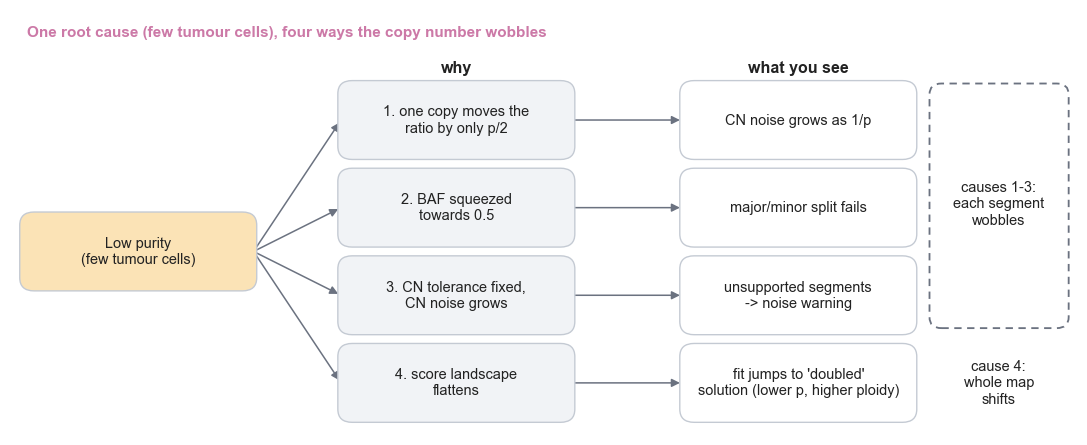

tumour used below: 98 true segments, ploidy 2.22


In [2]:
draw_concept_map()
print(f"tumour used below: {len(prof)} true segments, ploidy {PSI:.2f}")

| | 무엇이 일어나나 | 결과 |
|---|---|---|
| 원인 1 | copy 하나가 만드는 깊이 비 변화가 $p$ 에 비례해 작아진다. 잡음은 그대로다 | CN 잡음이 $1/p$ 배로 커진다 |
| 원인 2 | BAF 가 0.5 로 몰려 모호 판정 기준선 근처에 묻힌다 | major·minor 나눔이 틀린다. 아주 낮은 purity 에서는 깊이도 중요해진다 |
| 원인 3 | 잡음이 만든 가짜 끊김을, CN 단위로 정한 허용치 안에서 합쳐야 하는데 CN 단위 잡음이 커져 못 합친다 | 근거 없는 작은 구간이 늘어 `WARN_HIGH_COPY_NUMBER_NOISE` 로 이어진다 |
| 원인 4 | 점수 지형이 평평해지고, purity $p/(2-p)$·CN 두 배 해가 deviation 벌점에서 유리하다 | 답이 통째로 "낮은 purity, 높은 ploidy" 쪽으로 뒤집힌다 |

## 원인 1. 신호는 $p$ 에 비례해 줄고, 잡음은 그대로다

**한 줄 정의**: CN 이 하나 다른 두 구간의 깊이 비 차이(사다리 한 칸)는 $n_f p/2$ 로 purity 에 비례하는데, 깊이 비의 잡음 폭은 purity 와 상관없습니다.

**왜 문제인가**: 사다리 칸이 잡음 폭보다 좁아지면 CN 2 구간과 CN 3 구간의 깊이 비 분포가 겹칩니다. 겹친 만큼 CN 을 잘못 읽습니다.

**숫자로 따라가기** (ploidy 2, 칸 하나의 잡음 4%)

| purity | 사다리 한 칸 | 잡음 폭(CN 2 자리) | 한 칸 ÷ 잡음 |
|---|---|---|---|
| 0.8 | 0.40 | 0.04 | 10 |
| 0.2 | 0.10 | 0.04 | 2.5 |

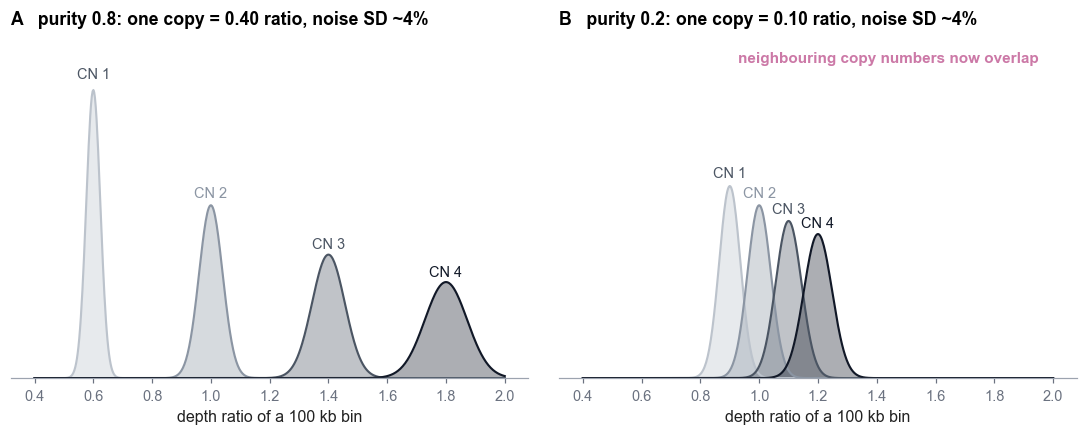

In [3]:
draw_ladder(sigma=0.04)

**그림에서 볼 것**: 왼쪽(purity 0.8)은 CN 1~4 의 깊이 비 분포가 뚝뚝 떨어져 있습니다. 오른쪽(purity 0.2)은 같은 잡음인데 분포끼리 겹칩니다.
겹친 자리의 칸은 CN 2 인지 3 인지 깊이 비만으로 정할 수 없습니다.

**식과 근거**: B1 에서 유도한 대로 깊이 비가 상대적으로 $\sigma$ 만큼 흔들리면 CN 은 $\sigma_{CN} = \dfrac{2 r \sigma}{p \cdot n_f} \approx \dfrac{2\sigma}{p}$ 만큼 흔들립니다 (`PurityAdjuster.purityAdjustedCopyNumber` 를 미분 [2]).
아래에서 시뮬레이션과 이 식을 비교합니다. 100 kb 칸 하나의 깊이 비 잡음은 계통 잡음 0.03, 독립 잡음 0.02, read 세기 잡음 $1/\sqrt{\text{read 수}}$ 를 합친 것입니다.
진짜 purity 와 normFactor 를 알려 준 상태에서 칸마다 CN 을 계산합니다.

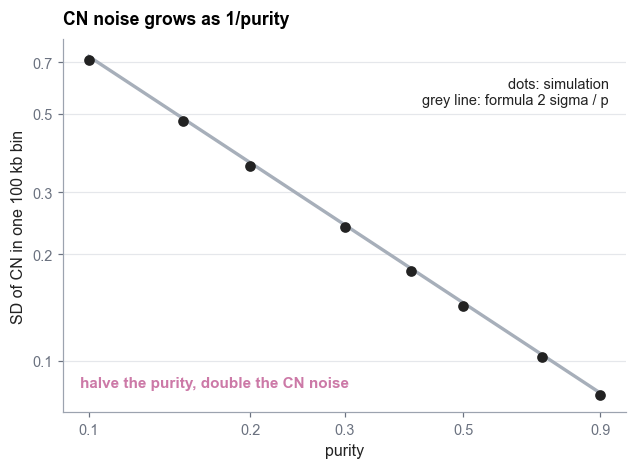

,purity,simulated,formula
0,0.90,0.080,0.081
1,0.70,0.102,0.104
2,0.50,0.143,0.146
3,0.40,0.179,0.182
4,0.30,0.239,0.243
5,0.20,0.356,0.364
6,0.15,0.477,0.485
7,0.10,0.713,0.728


In [4]:
lam = 60 * 1000 / pm.READ_LEN * pm.WINDOWS_PER_BIN        # 깊이 60 에서 칸 하나의 평균 read 수
sigma = np.sqrt(0.03 ** 2 + 0.02 ** 2 + 1 / lam)
rows = []
for p in [0.9, 0.7, 0.5, 0.4, 0.3, 0.2, 0.15, 0.1]:
    bins, _ = pm.simulate(prof, p, depth=60, seed=3)
    nf = pm.norm_factor(p, PSI)
    cn = pm.cn_from_ratio(bins.ratio, p, nf)
    m = bins.true_cn == 2
    rows.append(dict(purity=p, simulated=(cn[m] - 2).std(),
                     formula=2 * sigma * pm.ratio_from_cn(2, p, nf) / (p * nf)))
r1 = pd.DataFrame(rows)
assert np.allclose(r1.simulated / r1.formula, 1, atol=0.1)

fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.plot(r1.purity, r1.formula, color="#A7AFBA", lw=2.2)
ax.plot(r1.purity, r1.simulated, "o", color=COL["ink"], ms=7, mew=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks([0.1, 0.2, 0.3, 0.5, 0.9]); ax.set_xticklabels(["0.1", "0.2", "0.3", "0.5", "0.9"]); ax.minorticks_off()
ax.set_yticks([0.1, 0.2, 0.3, 0.5, 0.7]); ax.set_yticklabels(["0.1", "0.2", "0.3", "0.5", "0.7"])
ax.set_xlabel("purity"); ax.set_ylabel("SD of CN in one 100 kb bin"); ygrid(ax)
note(ax, 0.97, 0.9, "dots: simulation\ngrey line: formula 2 sigma / p", transform=ax.transAxes, ha="right", va="top", color=COL["ink"], fontsize=9.5)
callout(ax, 0.03, 0.06, "halve the purity, double the CN noise", transform=ax.transAxes, va="bottom")
panel(ax, "", "CN noise grows as 1/purity")
plt.show()
r1.round(3)

**그림에서 볼 것**: 점(시뮬레이션)이 회색 선(식) 위에 있습니다. 로그 눈금에서 기울기 −1 인 직선, 즉 $1/p$ 입니다.
purity 0.9 에서 칸 하나의 CN 은 0.08 정도 흔들리지만, purity 0.1 에서는 0.7 흔들려 이웃한 정수를 넘나듭니다.

이 시뮬레이션은 계통 잡음을 `sys_sd = 0.03` 으로 골랐고(B1 5절의 남은 GC 물결을 흉내 낸 모형 값), 그것이 잡음의 대부분입니다. 깊이 60 에서 칸 하나에 read 가 4 만 개 들어오므로 세기 잡음은 0.5% 밖에 안 됩니다.
그래서 이 시뮬레이션에서는 깊이를 올려도 이 줄이 거의 내려가지 않습니다. 실제 시료에서 계통 잡음이 얼마인지는 시료마다 다릅니다. 구간이 길면 여러 칸을 평균해 줄어들지만, 이웃 칸끼리 닮은 계통 잡음은 평균으로도 잘 줄지 않습니다.

**직접 바꿔 보기**: `draw_ladder(sigma=0.02)` 로 잡음을 반으로 줄여 보세요. purity 0.2 에서도 분포가 덜 겹칩니다. 잡음과 purity 가 **함께** 결과를 정합니다.

## 원인 2. BAF 가 0.5 로 몰려 major·minor 를 못 가른다

**한 줄 정의**: 총 CN 은 깊이 비에서, major·minor 나눔은 BAF 에서 옵니다. purity 가 낮으면 모든 상태의 BAF 가 0.5 로 몰려 균형 구간(1,1)과 구별되지 않습니다.

**숫자로 따라가기** (gain (2,1), 깊이 60)

| purity | (2,1) 의 기대 BAF | 모호 판정 기준선(접기 전 80 백분위) [2] |
|---|---|---|
| 0.8 | (1.6 + 0.2)/(2.4 + 0.4) = 0.643 | 0.556 |
| 0.15 | (0.3 + 0.85)/(0.45 + 1.7) = 0.535 | 0.556 |

purity 0.15 에서는 (2,1) 의 기대 BAF 가 기준선보다 낮습니다.

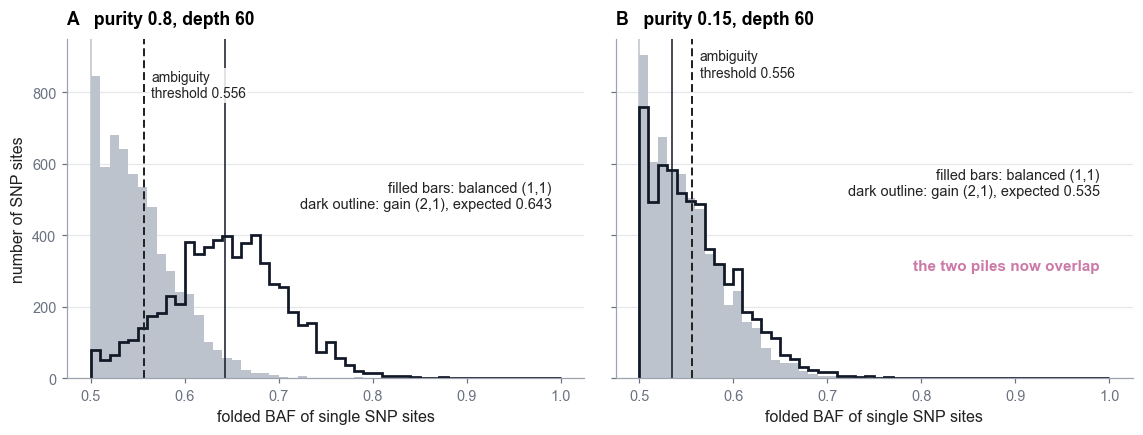

In [5]:
draw_baf_overlap(depth=60)
assert pm.expected_baf(0.15, 2, 1) < pm.ambiguous_baf(60) < pm.expected_baf(0.8, 2, 1)

**그림에서 볼 것**: 왼쪽(purity 0.8)은 균형(옅은 회색 막대)과 gain(진한 테두리) 분포가 갈라져 있습니다. 오른쪽(purity 0.15)은 두 분포가 거의 겹치고, gain 의 기대값(진한 세로선)이 검은 점선(모호 판정 기준선)보다 왼쪽에 있습니다.
자리 하나로는 못 가르고, 구간 안의 수백 자리를 모아 중앙값을 내도 기준선 근처라 깊이에 따라 결과가 갈립니다.
(기준선 이하이면 PURPLE 은 BAF 0.5 와 관찰값 가운데 벌점이 작은 쪽을 고릅니다 [2]. 균형 구간의 접힌 중앙값도 0.5 보다 조금 높다는 점은 B1 6절을 보세요.)

진짜 구간을 1 Mb(칸 10 개, BAF 점 약 300 개) 조각으로 잘라, 조각마다 minor CN 을 계산해 진짜와 비교합니다.
진짜 purity 와 normFactor 를 알려 준 상태라 맞추기 실수는 없고, 순수하게 데이터의 흔들림만 봅니다. 깊이 30, 60, 120 을 비교합니다.

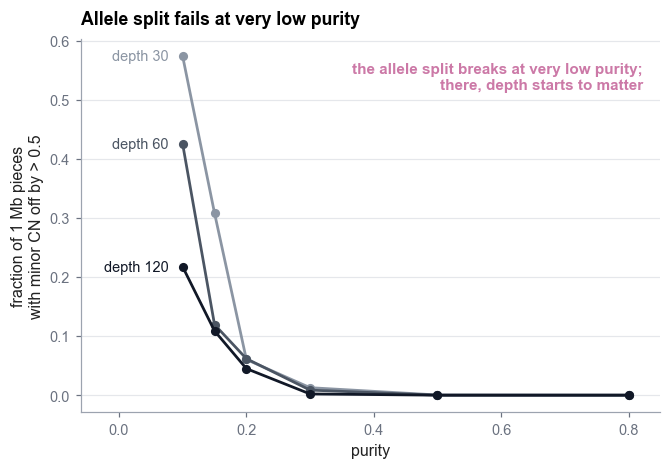

depth,30,60,120
purity,,,
0.80,0.00,0.00,0.00
0.50,0.00,0.00,0.00
0.30,0.01,0.01,0.00
0.20,0.06,0.06,0.04
0.15,0.31,0.12,0.11
0.10,0.57,0.42,0.22


In [6]:
def chop(profile, size=10):
    rows = []
    for _, r in profile.iterrows():
        for s in range(r.start_bin, r.end_bin, size):
            rows.append(dict(chromosome=r.chromosome, start_bin=s, end_bin=min(s + size, r.end_bin),
                             start_support="NONE", end_support="NONE", minor_true=r.minor))
    return pd.DataFrame(rows)

pieces = chop(prof)
rows = []
for depth in [30, 60, 120]:
    for p in [0.8, 0.5, 0.3, 0.2, 0.15, 0.1]:
        bins, bafs = pm.simulate(prof, p, depth=depth, seed=4)
        segs = pm.summarize(bins, bafs, pieces)
        nf = pm.norm_factor(p, PSI, np.average(segs.observedTumorRatio, weights=segs.bafCount.clip(lower=1)))
        f = pm.apply_fit(segs, p, nf, depth)
        err = (f.minorAlleleCopyNumber - pieces.minor_true).abs()
        rows.append(dict(depth=depth, purity=p, NRPCC=pm.nrpcc(depth, p, PSI),
                         median_error=err.median(), wrong_minor=(err > 0.5).mean()))
r2 = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.8, 4.4))
groups = list(r2.groupby("depth"))
for i, (depth, g) in enumerate(groups):
    g = g.sort_values("purity"); col = GREYS[len(groups) - 1 - i]
    ax.plot(g.purity, g.wrong_minor, "o-", color=col, ms=6, mew=0, lw=1.8)
    ax.annotate(f"depth {depth}", (g.purity.iloc[0], g.wrong_minor.iloc[0]), xytext=(-9, 0), textcoords="offset points",
                ha="right", va="center", fontsize=9.5, color=GREYS[min(len(groups) - 1 - i, 2)])
ax.set_xlim(-0.06, 0.85)
ax.set_xlabel("purity"); ax.set_ylabel("fraction of 1 Mb pieces\nwith minor CN off by > 0.5"); ygrid(ax)
callout(ax, 0.97, 0.94, "the allele split breaks at very low purity;\nthere, depth starts to matter", transform=ax.transAxes, ha="right", va="top")
panel(ax, "", "Allele split fails at very low purity")
plt.show()
r2.pivot(index="purity", columns="depth", values="wrong_minor").sort_index(ascending=False).round(2)

In [7]:
assert r2.query("purity == 0.1 and depth == 30").wrong_minor.iloc[0] > r2.query("purity == 0.1 and depth == 120").wrong_minor.iloc[0]
assert r2.query("purity == 0.8").wrong_minor.max() < 0.02
r2[["depth", "purity", "NRPCC", "median_error", "wrong_minor"]].round(3).sort_values(["purity", "depth"], ascending=[False, True])

,depth,purity,NRPCC,median_error,wrong_minor
0,30,0.80,11.010,0.017,0.000
6,60,0.80,22.019,0.016,0.000
12,120,0.80,44.038,0.015,0.000
1,30,0.50,7.101,0.030,0.000
7,60,0.50,14.202,0.030,0.000
13,120,0.50,28.403,0.029,0.000
2,30,0.30,4.353,0.051,0.013
8,60,0.30,8.706,0.052,0.009
14,120,0.30,17.413,0.050,0.002
3,30,0.20,2.934,0.076,0.060


**그림에서 볼 것**
- purity 0.2 위에서는 세 선이 거의 0 에 붙어 있습니다. 1 Mb 조각에는 BAF 점이 수백 개라 중앙값이 충분히 안정적입니다.
- purity 0.1 근처에서 선이 갈라집니다. BAF 신호가 기준선 근처라, 자리마다의 흔들림(깊이로 줄어드는 잡음)이 결과를 좌우합니다.

NRPCC(B1 7-4 [5])는 purity 와 깊이를 한 숫자로 묶은 것이라 이 경향을 대략 따라갑니다. 하지만 표에서 NRPCC 가 비슷해도(예: purity 0.2·깊이 30 과 purity 0.1·깊이 60, 둘 다 약 3) 결과가 다릅니다.
이 시뮬레이션에서는 **총 CN 흔들림은 주로 purity 가, 아주 낮은 purity 의 allele 나눔은 purity 와 깊이가 함께** 정했습니다.

## 원인 3. 가짜 구간이 합쳐지지 않는다 → CN noise 경고

**한 줄 정의**
- **PCF**(piecewise constant fit): 데이터를 "평균이 일정한 토막들"로 자르는 방법입니다. 토막 안 제곱오차 합에 토막 수만큼 벌점을 더한 값을 가장 작게 하는 자리에서 자릅니다 [3].
  PURPLE 은 깊이 비와 BAF 를 따로 PCF 로 자르고(gamma = 100), SV 끊김을 더해 처음 구간을 만듭니다 [1].
- **다듬기(smoothing)**: 이웃 구간의 CN 차이가 허용치 안이면 합칩니다. **SV 가 받치는 경계는 절대 넘지 않습니다** [1].
- **unsupported segment**: 양쪽 끝 모두 SV 근거가 없는 구간입니다. 220 개를 넘으면 `WARN_HIGH_COPY_NUMBER_NOISE` 가 붙습니다 [1].

**왜 purity 와 관련 있나**: 허용치가 **CN 단위로** 정해져 있기 때문입니다 (`AlleleTolerance.java` [1][2]). 허용치는 두 가지입니다($n$ = 두 구간 중 작은 쪽의 창 수).

$$\text{절대 허용치} = \max\!\left(1, \frac{0.2}{p}\right) \times \left(0.3 + \frac{1}{\sqrt{n}}\right) \;\text{copy}, \qquad
\text{상대 허용치} = \max\!\left(1, \frac{0.2}{p}\right) \times \left(0.12 + \frac{0.8}{\sqrt{n}}\right)$$

CN 차이가 절대 허용치 안이거나, **상대 차이**(차이 ÷ 작은 쪽 CN)가 상대 허용치 안이면 합칩니다. 정상 시료의 깊이 비로 보정한 CN 으로 다시 재서 안에 들어도 합칩니다
(코드: `copyNumberInTolerance || refNormalisedCopyNumberInTolerance` [2]). 이 노트북의 가짜 데이터에는 정상 시료 쪽 비가 따로 없어(어디나 이배체로 봄) 이 마지막 조건은 앞과 같습니다.

purity 0.2 위에서는 앞의 배수가 1 이라 허용치가 purity 와 상관없이 같습니다. 그런데 같은 깊이 비 물결이 CN 단위로는 $1/p$ 배로 커집니다(원인 1).
그래서 purity 가 낮으면 물결이 허용치를 넘어 **따로 남는 구간**이 됩니다. 설명서도 이 경고가 "Mb 규모와 kb 규모의 GC 편향" 같은 잡음으로 생길 수 있다고 적습니다 [1][6].

**숫자로 따라가기** (CN 2 이웃 기준; 깊이 비 물결 5%, 창 1,000 개짜리 구간끼리)

창 1,000 개면 절대 허용치는 0.33 copy, 상대 허용치는 0.145 입니다. CN 2 이웃에서 상대 허용치는 0.145 × 2 = 0.29 copy 라 절대 허용치(0.33)가 더 넉넉합니다.

| purity | 물결이 만드는 CN 차이 $2 \times 0.05/p$ | 허용치(둘 중 넓은 쪽) | 합쳐지나 |
|---|---|---|---|
| 0.7 | 0.14 | 0.33 | 합쳐짐 |
| 0.3 | 0.33 | 0.33 | 경계 |
| 0.25 | 0.40 | 0.33 | 따로 남음 |
| 0.1 | 1.00 | 0.66 | 따로 남음 |

**CN 이 높은 이웃은 다릅니다.** CN 4 이웃이면 상대 허용치가 0.145 × 4 = 0.58 copy 로 넓어집니다. purity 0.25 에서 같은 5% 물결이 CN 4 자리에 만드는 차이는
$2 \times 0.05 \times (1 + p)/p \approx 0.50$ copy 라 합쳐집니다. 위 표의 "따로 남음"은 CN 2 근처 구간에서의 이야기입니다.

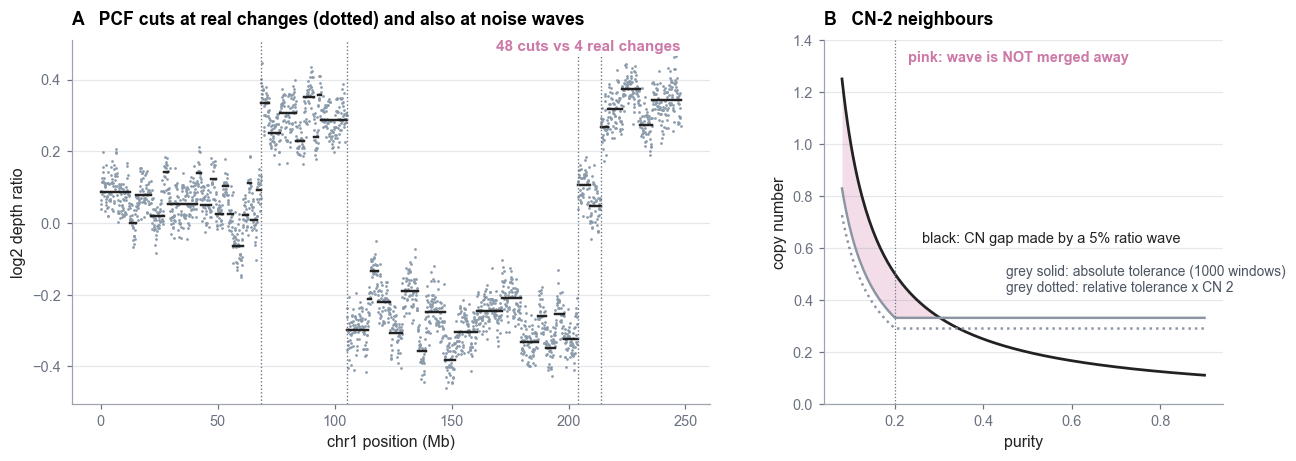

In [8]:
n_cuts, n_real = draw_pcf_and_tolerance(prof, wave=0.05, windows=1000)
assert n_cuts > n_real

**그림에서 볼 것**
- A: 회청색 점은 chr1 의 칸별 깊이 비(log2), 점선은 진짜 CN 이 바뀌는 자리, 검은 선은 PCF 토막입니다. PCF 는 진짜 변화 말고도 물결마다 자릅니다. 이 끊김들은 SV 근거가 없습니다.
- B (CN 2 이웃): 검은 선(같은 5% 물결이 만드는 CN 차이)이 두 회색 선(절대 허용치 실선, 상대 허용치 × CN 2 점선) 가운데 높은 쪽보다 위에 있으면(분홍 칠) 그 물결은 합쳐지지 않고 따로 남습니다.
  purity 0.3 아래에서 분홍 칠이 시작됩니다. 0.2 아래(purity 0.2 의 세로 점선 왼쪽)에서는 허용치도 $1/p$ 로 커져 두 선의 비율이 일정해집니다.

이제 전체 유전체로 확인합니다. 맞추기 실수와 섞이지 않게, 진짜 purity 와 normFactor 로 CN 을 매긴 뒤 다듬습니다. 계통 잡음 0.02 와 0.04 를 비교합니다.
**실제 도구와 다른 점**: `purple_mini` 의 구간 나누기는 100 kb 칸의 log2 깊이 비만 gamma 40 으로 자르고 BAF 는 자르지 않습니다(실제: 1 kb 깊이 비와 BAF 를 따로, gamma 100 [1]).
다듬기도 단순합니다. 실제 PURPLE 은 가장 믿을 만한 구간에서 양쪽으로 넓혀 가고, 30 창 미만의 애매한 작은 구간은 한꺼번에 흡수합니다 [1]. 그래서 **개수 자체**는 실제와 다르고 경향만 봐야 합니다.

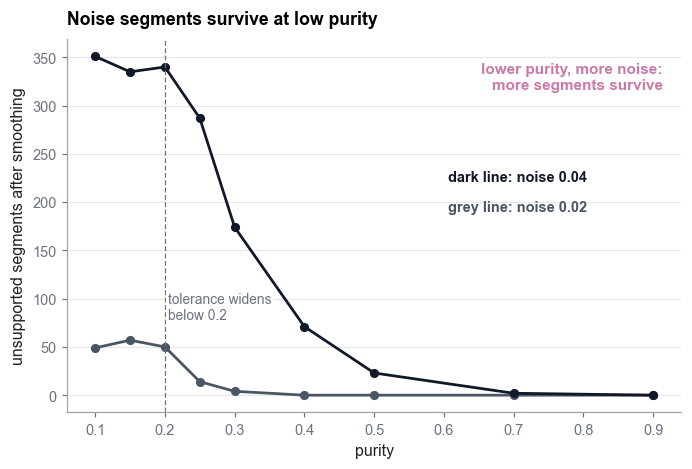

raw_segments      unsupported     
sys_sd         0.02 0.04        0.02 0.04
purity                                   
0.90            265  554           0    0
0.70            275  561           0    2
0.50            275  559           0   23
0.40            269  542           0   71
0.30            263  534           4  174
0.25            275  563          14  287
0.20            266  548          50  340
0.15            277  556          57  335
0.10            282  567          49  351

In [9]:
rows, examples = [], {}
for sd in [0.02, 0.04]:
    for p in [0.9, 0.7, 0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1]:
        bins, bafs = pm.simulate(prof, p, depth=60, sys_sd=sd, seed=2)
        segs = pm.summarize(bins, bafs, pm.segment(bins, prof))
        nf = pm.norm_factor(p, PSI, np.average(segs.observedTumorRatio, weights=segs.bafCount.clip(lower=1)))
        sm = pm.smooth(pm.apply_fit(segs, p, nf), p)
        rows.append(dict(sys_sd=sd, purity=p, raw_segments=len(segs), smoothed_segments=len(sm),
                         unsupported=pm.unsupported_segments(sm)))
        if sd == 0.04 and p in (0.7, 0.25):
            examples[p] = sm
r3 = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7.2, 4.4))
groups = list(r3.groupby("sys_sd"))
for i, (sd, g) in enumerate(groups):
    g = g.sort_values("purity"); k = len(groups) - 1 - i       # 잡음이 클수록 진하게
    ax.plot(g.purity, g.unsupported, "o-", color=GREYS[k], ms=6, mew=0, lw=1.8)
    note(ax, 0.62, 0.62 - 0.08 * k, f"{'dark' if k == 0 else 'grey'} line: noise {sd}", transform=ax.transAxes,
         color=GREYS[min(k, 2)], fontsize=9.5, weight="semibold")
ax.axvline(0.2, color=COL["muted"], lw=0.8, ls=(0, (4, 2)))
note(ax, 0.205, 0.25, "tolerance widens\nbelow 0.2", transform=ax.get_xaxis_transform(), fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("purity"); ax.set_ylabel("unsupported segments after smoothing"); ygrid(ax)
callout(ax, 0.97, 0.94, "lower purity, more noise:\nmore segments survive", transform=ax.transAxes, ha="right", va="top")
panel(ax, "", "Noise segments survive at low purity")
plt.show()
r3.pivot(index="purity", columns="sys_sd", values=["raw_segments", "unsupported"]).sort_index(ascending=False)

In [10]:
u = r3.set_index(["sys_sd", "purity"]).unsupported
assert u[(0.04, 0.25)] > u[(0.04, 0.7)] + 50
assert u[(0.02, 0.9)] <= 5

**그림에서 볼 것**
- **다듬은 뒤 남는 근거 없는 구간**은 purity 가 낮을수록 늘어납니다. 잡음이 클수록(진한 선) 더 일찍, 더 많이 늘어납니다.
- purity 0.2 아래에서는 허용치가 넓어져 증가가 멈춥니다. 대신 이 구간에서는 `WARN_LOW_PURITY`(purity 0.2 미만 [1])가 붙습니다.
- 표의 **처음 구간 수**(`raw_segments`)는 purity 와 상관없이 비슷합니다. PCF 는 깊이 비의 상대 잡음만 보기 때문입니다.

같은 종양을 purity 0.7 과 0.25 로 다듬은 결과를 앞쪽 다섯 염색체만 그려 봅니다. 회색 굵은 선이 진짜 CN 입니다.

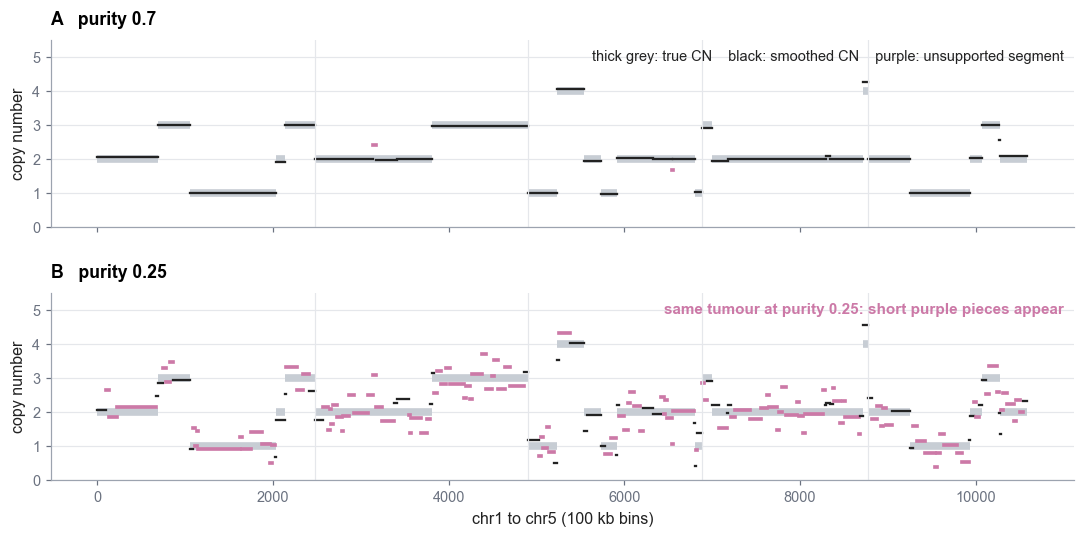

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True, gridspec_kw={"hspace": 0.35})
chroms = ["1", "2", "3", "4", "5"]
offset = dict(zip(chroms, np.cumsum([0] + [pm.CHROM_MB[int(c) - 1] * 10 for c in chroms[:-1]])))
for ax, letter, p in zip(axes, "AB", [0.7, 0.25]):
    sm = examples[p][examples[p].chromosome.isin(chroms)]
    tp = prof[prof.chromosome.isin(chroms)]
    for _, r in tp.iterrows():
        o = offset[r.chromosome]; ax.plot([o + r.start_bin, o + r.end_bin], [r.major + r.minor] * 2, color="#C7CDD4", lw=5, solid_capstyle="butt")
    for _, r in sm.iterrows():
        o = offset[r.chromosome]
        bad = r.start_support == "NONE" and r.end_support == "NONE"
        ax.plot([o + r.start_bin, o + r.end_bin], [r.tumorCopyNumber] * 2, color=COL["highlight"] if bad else COL["ink"], lw=2.4 if bad else 1.5)
    for c in chroms[1:]:
        ax.axvline(offset[c], color=COL["grid"], lw=0.8)
    ax.set_ylabel("copy number"); ax.set_ylim(0, 5.5); ygrid(ax)
    panel(ax, letter, f"purity {p}")
note(axes[0], 0.99, 0.95, "thick grey: true CN    black: smoothed CN    purple: unsupported segment",
     transform=axes[0].transAxes, ha="right", va="top", color=COL["ink"], fontsize=9.5)
callout(axes[1], 0.99, 0.95, "same tumour at purity 0.25: short purple pieces appear", transform=axes[1].transAxes, ha="right", va="top")
axes[1].set_xlabel("chr1 to chr5 (100 kb bins)")
plt.show()

**그림에서 볼 것**: purity 0.7 에서는 다듬은 CN(검은 선)이 진짜 계단을 그대로 따라갑니다. purity 0.25 에서는 같은 자리에 짧은 자주색 구간(근거 없는 구간)이 생기고 CN 이 위아래로 흔들립니다.
**같은 종양, 같은 잡음인데 purity 만 낮아졌을 뿐입니다.**

## 원인 4. 점수 지형이 평평해지고, 두 배 해가 이긴다

**한 줄 정의**: B2 7절의 "두 배 해"(purity $p/(2-p)$, CN 모두 두 배)가 잡음 섞인 데이터에서 진짜 해보다 deviation 벌점을 덜 받아, event 벌점의 불리함을 넘어서는 현상입니다.

**왜 두 배 해가 유리한가**: 두 가지가 겹칩니다.
1. 두 배 해는 CN 이 두 배라 **허용되는 깊이 비 단계가 두 배 촘촘합니다.** 잡음으로 어긋난 구간도 어느 단계에든 가까이 떨어지기 쉽습니다.
2. 두 배 해는 purity 가 낮아 copy 하나를 표준편차 더 적은 개수로 봅니다(B2 4절). 같은 거리에도 벌점이 덜 오릅니다.

**숫자로 따라가기** (진짜 purity 0.30, ploidy 2.24 → 두 배 해 purity 0.18, ploidy 4.48; 구간 깊이 비 오차 0.05)

| | 단계 간격 | copy 하나 = SD | 0.05 오차의 정수까지 거리 | 벌점 |
|---|---|---|---|---|
| 진짜 해 | 0.145 | 2.9 | 0.34 copy | 0.68 |
| 두 배 해 | 0.073 | 1.5 | 0.31 copy | 0.36 |

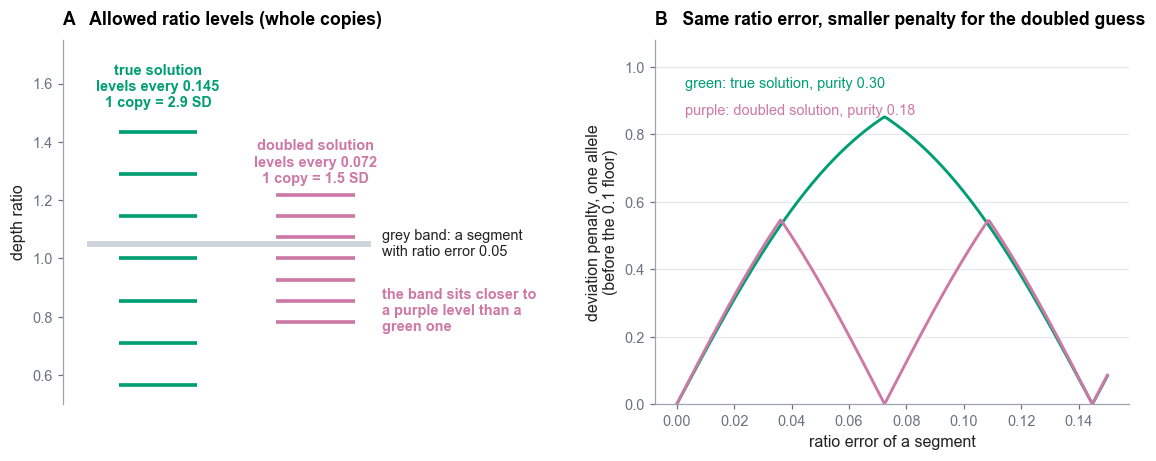

In [12]:
draw_why_doubled_wins(true_p=0.3, true_psi=2.24)

**그림에서 볼 것**
- A: 초록(진짜 해)의 허용 단계는 0.145 간격, 자주(두 배 해)는 그 절반 간격입니다. 회색 띠(오차 0.05 인 구간)는 초록 단계 사이에서 1.0 쪽으로 약 1/3 지점이라 가장 가까운 초록 단계(1.0)까지 0.05 떨어져 있지만, 가장 가까운 자주 단계(1.072)까지는 0.022 입니다.
- B: 오차가 약 0.035~0.11 사이이면 두 배 해의 벌점(자주)이 진짜 해(초록)보다 낮습니다(0.11 을 넘으면 다시 진짜 해가 낮아집니다). 잡음이 큰 시료일수록 이런 구간이 많아집니다.

점수는 **곱**(event × deviation)이라 비율로 따집니다. 두 배 해는 (1,1) 이 (2,2) 가 되는 등 event 벌점이 커서, B2 의 예에서는 진짜 해의 약 1.49 배였습니다(1.899 ÷ 1.272).
그러니 진짜 해의 deviation 벌점이 두 배 해의 약 1.5 배를 넘으면 답이 뒤집힙니다(정확한 배수는 종양마다 다름).
purity 와 잡음을 바꿔 가며 처음부터(구간 나누기 포함) 맞춰 봅니다. 시드 세 개씩 돌립니다. 1 분쯤 걸립니다.

In [13]:
rows, keep = [], {}
for sd in [0.02, 0.05]:
    for p in [0.6, 0.45, 0.3, 0.2]:
        for seed in [1, 2, 3]:
            bins, bafs = pm.simulate(prof, p, depth=60, sys_sd=sd, seed=seed)
            segs = pm.summarize(bins, bafs, pm.segment(bins, prof))
            fits = pm.fit(segs, 60)
            s = pm.summary(fits)
            rows.append(dict(sys_sd=sd, true_purity=p, seed=seed, fit_purity=s["purity"], fit_ploidy=s["ploidy"],
                             min_purity=s["minPurity"], max_purity=s["maxPurity"]))
            if seed == 1 and (sd, p) in [(0.02, 0.6), (0.05, 0.3)]:
                keep[(sd, p)] = fits
r4 = pd.DataFrame(rows)
r4["doubled_purity"] = r4.true_purity / (2 - r4.true_purity)
r4["flipped"] = (r4.fit_purity - r4.doubled_purity).abs() < (r4.fit_purity - r4.true_purity).abs()
r4.round(2)

,sys_sd,true_purity,seed,fit_purity,fit_ploidy,min_purity,max_purity,doubled_purity,flipped
0,0.02,0.60,1,0.61,2.24,0.59,0.62,0.43,False
1,0.02,0.60,2,0.61,2.24,0.59,0.62,0.43,False
2,0.02,0.60,3,0.61,2.24,0.59,0.62,0.43,False
3,0.02,0.45,1,0.46,2.24,0.44,0.47,0.29,False
4,0.02,0.45,2,0.46,2.24,0.44,0.47,0.29,False
5,0.02,0.45,3,0.46,2.24,0.44,0.47,0.29,False
6,0.02,0.30,1,0.31,2.24,0.29,0.32,0.18,False
7,0.02,0.30,2,0.31,2.26,0.30,0.32,0.18,False
8,0.02,0.30,3,0.31,2.24,0.29,0.32,0.18,False
9,0.02,0.20,1,0.21,2.26,0.20,0.22,0.11,False


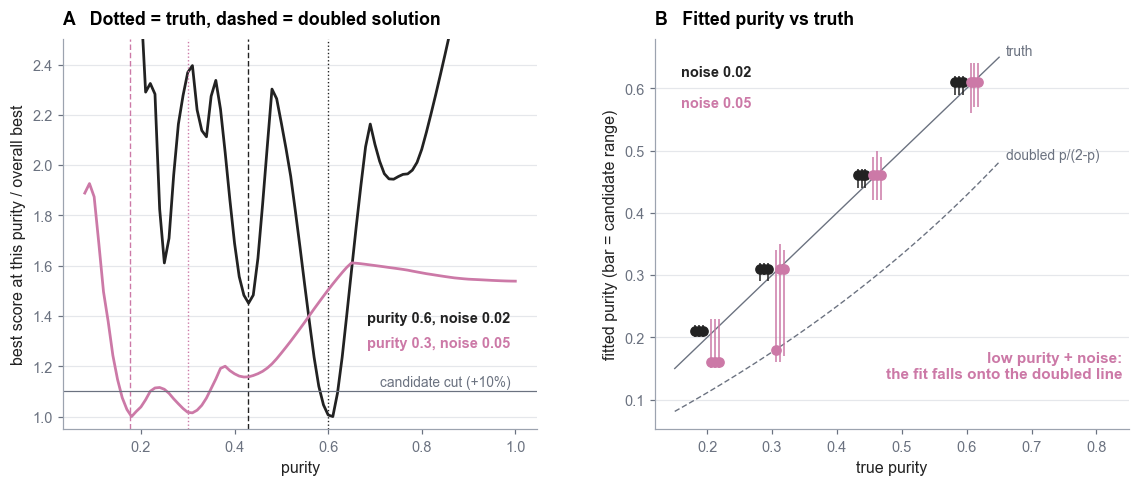

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"wspace": 0.25})
ax = axes[0]
PAIR = [COL["ink"], COL["highlight"]]          # 쉬운 경우 검정, 어려운 경우 자주
for i, ((sd, p), fits) in enumerate(keep.items()):
    b = pm.best_fit_per_purity(fits)
    ax.plot(b.purity, b.score / b.score.min(), color=PAIR[i], lw=1.8)
    ax.axvline(p, color=PAIR[i], lw=0.9, ls=":"); ax.axvline(p / (2 - p), color=PAIR[i], lw=0.9, ls=(0, (4, 2)))
    note(ax, 0.99, 1.42 - 0.1 * i, f"purity {p}, noise {sd}", ha="right", va="top", color=PAIR[i], fontsize=9.5, weight="semibold")
ax.axhline(1.1, color=COL["muted"], lw=0.8); note(ax, 0.99, 1.12, "candidate cut (+10%)", ha="right")
ax.set_ylim(0.95, 2.5); ax.set_xlabel("purity"); ax.set_ylabel("best score at this purity / overall best"); ygrid(ax)
panel(ax, "A", "Dotted = truth, dashed = doubled solution")

ax = axes[1]
pp = np.linspace(0.15, 0.65, 50)
ax.plot(pp, pp, color=COL["muted"], lw=0.9)
ax.plot(pp, pp / (2 - pp), color=COL["muted"], lw=0.9, ls=(0, (4, 2)))
note(ax, 0.66, 0.66, "truth", va="center"); note(ax, 0.66, 0.66 / 1.34, "doubled p/(2-p)", va="center")
for i, (sd, g) in enumerate(r4.groupby("sys_sd")):
    jit = (g.seed - 2) * 0.006 + (i - 0.5) * 0.024         # 잡음 수준끼리 좌우로 벌려 겹치지 않게
    ax.errorbar(g.true_purity + jit, g.fit_purity, yerr=[g.fit_purity - g.min_purity, g.max_purity - g.fit_purity],
                fmt="o", ms=6, color=PAIR[min(i, 1)], elinewidth=1.0, capsize=0)
    note(ax, 0.16, 0.62 - 0.05 * i, f"noise {sd}", color=PAIR[min(i, 1)], fontsize=9.5, weight="semibold")
ax.set_xlim(0.12, 0.85); ax.set_xlabel("true purity"); ax.set_ylabel("fitted purity (bar = candidate range)"); ygrid(ax)
panel(ax, "B", "Fitted purity vs truth")
callout(ax, 0.84, 0.13, "low purity + noise:\nthe fit falls onto the doubled line", ha="right", va="bottom")
plt.show()

In [15]:
assert not r4.query("true_purity == 0.6").flipped.any()
low = r4.query("sys_sd == 0.05 and true_purity <= 0.3")
# 잡음이 크고 purity 가 낮으면: ploidy 가 진짜보다 0.3 이상 높게 잡히거나, 후보 범위가 두 배 해까지 내려온다
assert ((low.fit_ploidy > PSI + 0.3) | (low.min_purity <= low.doubled_purity + 0.02)).all()
assert r4.query("sys_sd == 0.05 and true_purity == 0.3").flipped.any()
print(r4.groupby(["sys_sd", "true_purity"]).flipped.sum().unstack())

true_purity  0.20  0.30  0.45  0.60
sys_sd                             
0.02            0     0     0     0
0.05            0     1     0     0


**그림에서 볼 것**
- 왼쪽: purity 마다 가장 좋은 점수를 전체 최저 점수로 나눈 것입니다. 진짜 purity 0.6, 잡음 0.02(검은 선)는 진짜 purity(점선)에 뾰족한 골짜기가 있고, 두 배 해(파선)는 10% 선보다 훨씬 위입니다.
  진짜 purity 0.3, 잡음 0.05(자주색 선)는 곡선이 평평하고, 두 배 해 자리의 점수가 진짜 해와 비슷하거나 더 낮습니다.
- 오른쪽: 잡음이 크고 purity 가 낮으면 맞춘 purity 가 **두 배 해 선(파선)** 위로 떨어지는 경우가 생깁니다. 뒤집히지 않은 경우에도 후보 범위(막대)가 두 배 해까지 길게 내려옵니다.
  PURPLE 스스로도 "이 둘을 못 가르겠다"고 말하고 있는 것입니다.

표를 자세히 보면 이렇습니다(이 노트북의 시뮬레이션 결과).

- 진짜 purity 0.3, 잡음 0.05: 세 번 중 한 번 purity 0.18, ploidy 4.05 로 뒤집혔습니다. 나머지 두 번도 후보 범위가 0.16~0.17 까지 내려와 두 배 해(0.18)를 품고 있습니다.
- 진짜 purity 0.2, 잡음 0.05: 세 번 모두 purity 0.16, ploidy 2.7~3.0 으로 잡혔습니다. 두 배 해(0.11) 까지 가지는 않았지만 방향은 같습니다. **purity 는 낮게, ploidy 는 높게.**
- 잡음 0.02 에서는 purity 0.2 까지도 진짜 해를 찾았습니다. 잡음과 낮은 purity 가 **함께** 있어야 무너집니다.

다른 도구가 purity 0.5·ploidy 2.1 로 본 종양을 PURPLE 이 purity 0.33·ploidy 4 근처로 본다면, 이 패턴을 먼저 의심해 볼 만합니다($0.5/(2-0.5) = 0.33$).
이런 모호성은 PURPLE 만의 문제가 아닙니다. ABSOLUTE 논문은 여러 해가 같은 copy ratio 를 만든다고 적고 [4], Sequenza 논문은 ploidy 일치도가 대안 해를 사람이 살펴본 뒤에야 크게 올랐다고 보고합니다(r 0.42 → 0.94) [7].
반대로 진짜 WGD 종양도 있으므로, 두 답 중 어느 쪽이 맞는지는 다른 근거로 가려야 합니다(다음 절).

## 체세포 SNV 로 확인하기

**한 줄 정의**: VAF(variant allele frequency)는 체세포 변이 자리에서 변이를 가진 read 의 비율입니다. 모든 종양 세포에 있는(클론) 변이의 VAF 는 purity 와 그 자리 copy 수, 변이가 실린 copy 수로 정해집니다.

**왜 두 해를 가르나**: 깊이 비와 BAF 는 두 해에서 똑같지만(B2 7절), VAF 봉우리의 **개수**는 다릅니다.
이배체 종양(purity 0.3)의 클론 변이는 2 copy 중 1 copy 에 실려 VAF 봉우리가 하나($p/2$ = 0.15)입니다.
WGD 종양이라면 WGD **전에** 생겨 함께 두 배가 된 변이(4 copy 중 2)와 **뒤에** 생긴 변이(4 copy 중 1)가 서로 다른 봉우리를 만들어야 합니다.
ABSOLUTE 논문도 변이 데이터가 genome doubling 모호성을 가르는 데 도움이 된다고 적습니다 [4].

**숫자로 따라가기** (진짜 purity 0.30, 두 배 해 purity 0.176)

| 설명 | 변이가 실린 copy | VAF |
|---|---|---|
| 이배체, CN 2 | 1 of 2 | 0.30 × 1 / (0.30 × 2 + 1.40) = 0.150 |
| WGD, CN 4, WGD 전 | 2 of 4 | 0.176 × 2 / (0.176 × 4 + 1.647) = 0.150 |
| WGD, CN 4, WGD 뒤 | 1 of 4 | 0.176 × 1 / 2.353 = 0.075 |

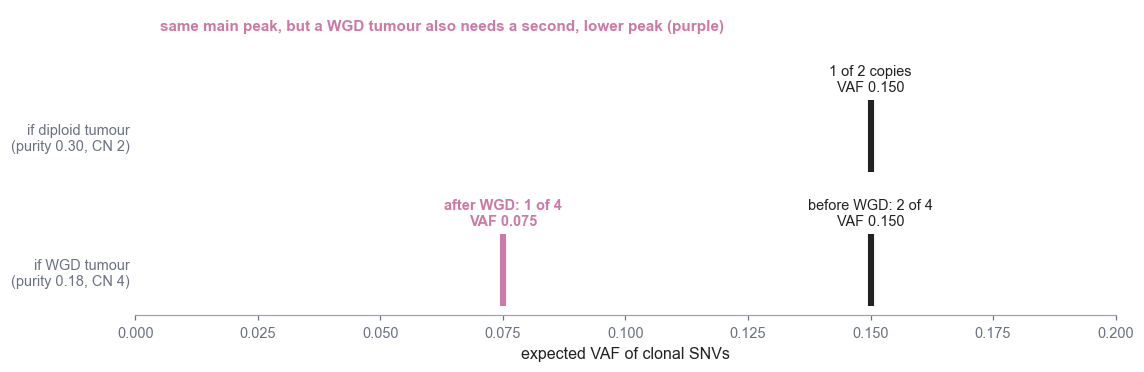

In [16]:
dip, pre, post = draw_vaf_expectation(p=0.3)
assert np.isclose(dip, pre) and np.isclose(post, pre / 2)

**그림에서 볼 것**: 두 설명 모두 VAF 0.15 에 큰 봉우리가 있습니다. WGD 설명이 맞다면 0.075 에 **두 번째 봉우리**가 있어야 합니다.
큰 봉우리 위치가 같으므로 "가장 높은 봉우리 × 2"로 잰 purity 는 두 설명 모두에서 약 0.30 이 됩니다. 그래서 **CN purity 와 SNV purity 의 차이는 두 해를 가르지 못합니다.**
가를 수 있는 근거는 **0.075 근처 낮은 봉우리가 있느냐 없느냐**입니다.

PURPLE 의 "SNV purity" 도 이 큰 봉우리를 씁니다: 깊이가 평균의 0.8~1.2 배인 SNV 의 VAF 분포에서 봉우리를 찾고, 무게가 충분한(SNV 수의 3% 와 4 개 가운데 큰 값보다 많은) 봉우리 가운데 가장 높은 것의 두 배를 purity 로 봅니다 (`SomaticPurityFitter.java` [1][2]).

아래에서 두 종양을 만들어 깊이 60 과 150 에서 비교합니다.
- **이배체 종양**: 원인 4 에서 뒤집혔던 종양(진짜 purity 0.30). 모든 클론 변이를 1 copy 에만 실었습니다(`simulate_snvs(clonal_mult=1)`). 그러니 이 종양에 낮은 봉우리가 없는 것은 **설계상 당연합니다.**
- **진짜 WGD 종양**(비교용): 같은 종양의 CN 을 모두 두 배로 하고 purity 0.176 으로 둔 뒤, 변이 2,000 개는 WGD 전(2 copy), 1,000 개는 WGD 뒤(1 copy)에 실었습니다. 이 비율도 이 노트북이 고른 값입니다.

copy-number fit of the diploid tumour: purity 0.18, ploidy 4.05


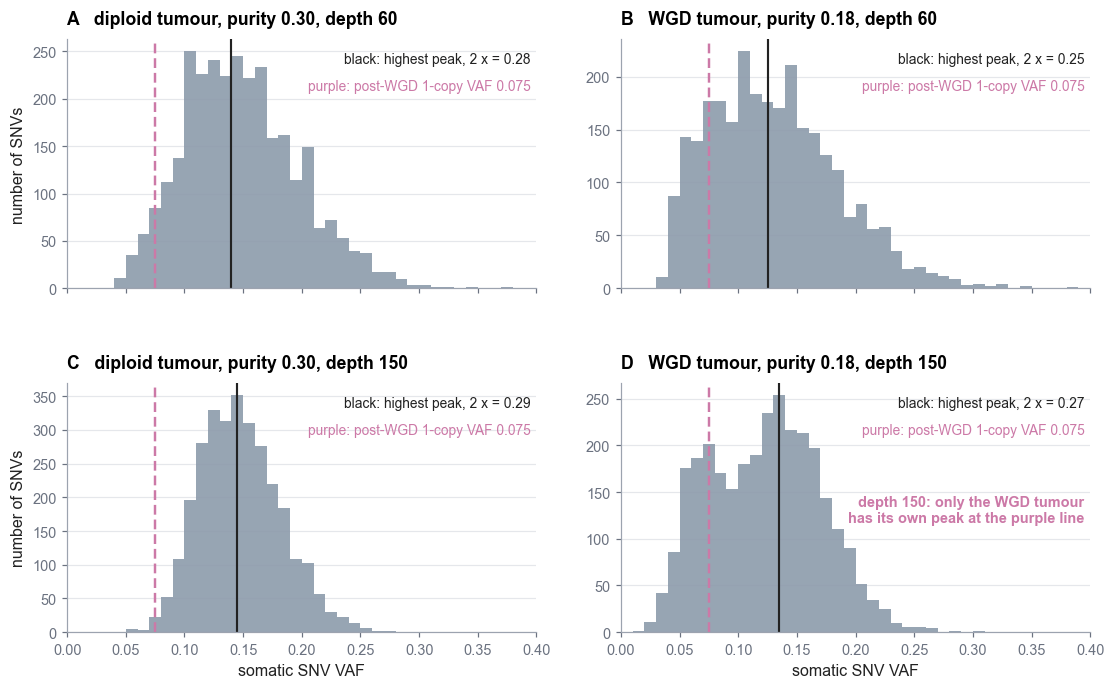

,depth,tumour,snv_purity_2x_peak,share_vaf_005_010
0,60,diploid tumour,0.28,0.155
1,60,WGD tumour,0.25,0.298
2,150,diploid tumour,0.29,0.068
3,150,WGD tumour,0.27,0.299


In [17]:
flip = r4.query("sys_sd == 0.05 and true_purity == 0.3").sort_values("fit_purity").iloc[0]
print(f"copy-number fit of the diploid tumour: purity {flip.fit_purity:.2f}, ploidy {flip.fit_ploidy:.2f}")
p_dbl = 0.3 / (2 - 0.3)
prof_wgd = prof.assign(major=prof.major * 2, minor=prof.minor * 2)
low = lambda s: float(((s.vaf >= 0.05) & (s.vaf <= 0.10)).mean())     # 낮은 봉우리 자리(0.075 근처)에 있는 SNV 비율
post_wgd = p_dbl / (4 * p_dbl + 2 * (1 - p_dbl))                        # CN 4 자리에서 1 copy 에만 있는 변이의 VAF

fig, axes = plt.subplots(2, 2, figsize=(12, 7.0), sharex=True, gridspec_kw={"hspace": 0.38, "wspace": 0.18})
rows = []
for r, depth in enumerate([60, 150]):
    snv_dip = pm.simulate_snvs(prof, 0.3, depth=depth, n=3000, seed=5)
    snv_wgd = pd.concat([pm.simulate_snvs(prof_wgd, p_dbl, depth=depth, n=2000, clonal_mult=2, seed=6),
                         pm.simulate_snvs(prof_wgd, p_dbl, depth=depth, n=1000, clonal_mult=1, seed=7)], ignore_index=True)
    for c, (title, s, col) in enumerate([("diploid tumour, purity 0.30", snv_dip, COL["read"]),
                                         (f"WGD tumour, purity {p_dbl:.2f}", snv_wgd, COL["read"])]):
        sp = pm.somatic_purity(s, depth)
        rows.append(dict(depth=depth, tumour=title.split(",")[0], snv_purity_2x_peak=sp, share_vaf_005_010=low(s)))
        ax = axes[r, c]
        ax.hist(s.vaf, bins=np.arange(0, 0.6, 0.01), color=col, alpha=0.9, lw=0)
        ax.axvline(sp / 2, color=COL["ink"], lw=1.4)
        ax.axvline(post_wgd, color=COL["highlight"], ls=(0, (4, 2)), lw=1.6)
        top = ax.get_ylim()[1]
        note(ax, 0.395, top * 0.95, f"black: highest peak, 2 x = {sp:.2f}", ha="right", va="top", color=COL["ink"], fontsize=9)
        note(ax, 0.395, top * 0.84, f"purple: post-WGD 1-copy VAF {post_wgd:.3f}", ha="right", va="top", color=COL["highlight"], fontsize=9)
        panel(ax, "ABCD"[2 * r + c], f"{title}, depth {depth}"); ax.set_xlim(0, 0.4); ygrid(ax)
for ax in axes[1]:
    ax.set_xlabel("somatic SNV VAF")
for ax in axes[:, 0]:
    ax.set_ylabel("number of SNVs")
callout(axes[1, 1], 0.395, axes[1, 1].get_ylim()[1] * 0.55, "depth 150: only the WGD tumour\nhas its own peak at the purple line", ha="right", va="top", fontsize=9.5)
plt.show()
snv_tab = pd.DataFrame(rows)
snv_tab.round(3)

In [18]:
t = snv_tab.set_index(["depth", "tumour"])
for d in [60, 150]:
    sp_dip, sp_wgd = t.loc[(d, "diploid tumour"), "snv_purity_2x_peak"], t.loc[(d, "WGD tumour"), "snv_purity_2x_peak"]
    assert abs(sp_dip - sp_wgd) < 0.05 and sp_wgd > p_dbl + 0.05      # 봉우리 x 2 는 두 종양에서 비슷하고, WGD 종양의 진짜 purity(0.18)와 멀다
assert t.loc[(150, "WGD tumour"), "share_vaf_005_010"] > 3 * t.loc[(150, "diploid tumour"), "share_vaf_005_010"]
assert t.loc[(60, "WGD tumour"), "share_vaf_005_010"] < 2.5 * t.loc[(60, "diploid tumour"), "share_vaf_005_010"]

**그림에서 볼 것**
- 네 그림 모두 큰 봉우리가 0.13~0.15 근처라 "가장 높은 봉우리 × 2"(검은 선)는 0.25~0.29 로 비슷합니다. 진짜 WGD 종양의 purity 는 0.18 인데도 그렇습니다. 이 규칙은 이배체를 가정하기 때문입니다.
  이유: WGD 전 변이(2 copy)의 VAF 는 자리마다 이배체 해의 1 copy 변이 VAF 와 정확히 같습니다(B2 7절의 두 배 해 등가). 새로 생기는 것은 WGD 뒤 변이의 낮은 봉우리뿐입니다.
- 차이는 자주색 파선(0.075) 자리입니다. 깊이 150(아래)에서는 WGD 종양에 따로 선 봉우리가 보이고, 이배체 종양에는 큰 봉우리의 왼쪽 비탈만 있습니다.
- 깊이 60(위)에서는 두 봉우리가 섞여 낮은 봉우리가 큰 봉우리의 왼쪽 어깨처럼 보입니다. VAF 0.15 자리에서 read 를 뽑는 흔들림(표준편차 $\sqrt{0.15 \times 0.85 / 60} \approx 0.046$)이 두 봉우리 간격 0.075 와 비슷하기 때문입니다.
  이 깊이에서는 0.05~0.10 구간의 SNV 비율이 WGD 종양에서 2 배쯤 많은 정도로만 드러납니다(표). 표와 그림의 숫자는 이 노트북의 시뮬레이션 결과입니다.

정리하면, PURPLE 이 "낮은 purity·높은 ploidy" 를 냈을 때 그 답이 두 배 해로 뒤집힌 것인지는 **낮은 VAF 쪽의 따로 선 봉우리**로 판단합니다.

실제 데이터에서는 이 판단에도 한계가 있습니다.
- **subclone 꼬리**: 일부 종양 세포에만 있는 변이는 낮은 VAF 쪽에 꼬리를 만들어, WGD 뒤 봉우리처럼 보일 수 있습니다.
- **gain 안의 2 copy 변이**: gain 전에 생긴 변이는 늘어난 copy 에 함께 실려 $p/2$ 보다 높은 봉우리를 만듭니다. 이런 봉우리가 가장 높은 봉우리로 잡히면 "× 2" 규칙이 purity 를 부풀립니다.
- 이 노트북의 두 종양은 이런 효과를 넣지 않은 단순한 모형입니다.

PURPLE 은 **제한된 조건에서만** SNV purity 로 자동으로 바꿉니다 [1].
- 후보 해 가운데 거의 다 이배체(구간의 97% 이상이 1+1)인 해가 있고, 후보 purity 범위가 0.15 이상 넓으며, SNV 파일이 있을 때 SNV 맞추기를 합니다.
- SOMATIC 방식으로 바꾸면 ploidy 를 2 로 고정합니다.
- SNV purity 와 CN purity 가 **둘 다 0.17 미만이고 SNV purity 가 더 크면**, 또는 조건에 맞는 SNV 가 없거나 동형접합 결실이 지나치게 많아지면, 다시 CN 맞추기(NORMAL)로 돌아갑니다.

그러니 이배체가 아닌 두 배 해 의심 시료는 대개 자동으로 바뀌지 않고, 사람이 확인해야 합니다.
(PURPLE 은 맞추기 점수에 "SNV 의 copy 수가 major 보다 크면 벌점"을 더하는 장치도 갖고 있지만 [1], 이 노트북의 `purple_mini` 는 그 항을 뺐습니다.)

SNV 로 purity 를 재는 방법에는 탐지 한계도 있습니다. purity 가 아주 낮으면 VAF 가 $p/2$ 로 작아져, alt read 가 몇 개 이상인 변이만 찾히는 **탐지 한계**에 걸립니다.
찾힌 변이만 보면 VAF 가 실제보다 높아 보여 purity 를 부풀립니다.

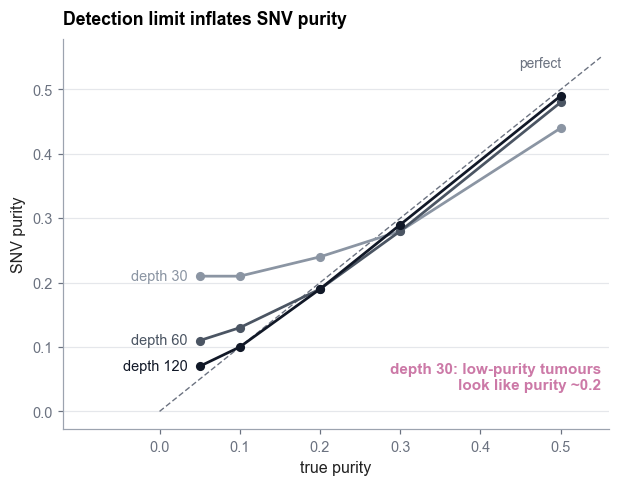

depth,30,60,120
true_purity,,,
0.05,0.21,0.11,0.07
0.10,0.21,0.13,0.10
0.20,0.24,0.19,0.19
0.30,0.28,0.28,0.29
0.50,0.44,0.48,0.49


In [19]:
rows = []
for depth in [30, 60, 120]:
    for p in [0.05, 0.1, 0.2, 0.3, 0.5]:
        rows.append(dict(depth=depth, true_purity=p,
                         snv_purity=pm.somatic_purity(pm.simulate_snvs(prof, p, depth=depth, n=3000, seed=5), depth)))
r5 = pd.DataFrame(rows).pivot(index="true_purity", columns="depth", values="snv_purity")
assert r5.loc[0.05, 30] > 0.1 and abs(r5.loc[0.3, 120] - 0.3) < 0.03

fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.plot([0, 0.55], [0, 0.55], color=COL["muted"], lw=0.9, ls=(0, (4, 2)))
note(ax, 0.5, 0.53, "perfect", ha="right", va="bottom")
for i, d in enumerate(r5.columns):
    k = len(r5.columns) - 1 - i                    # 얕을수록 진하게: 문제가 되는 쪽을 눈에 띄게
    ax.plot(r5.index, r5[d], "o-", color=GREYS[k], ms=6, mew=0, lw=1.8)
    ax.annotate(f"depth {d}", (r5.index[0], r5[d].iloc[0]), xytext=(-8, 0), textcoords="offset points",
                ha="right", va="center", fontsize=9.5, color=GREYS[min(k, 2)])
ax.set_xlim(-0.12, 0.56); ax.set_xticks([0, 0.1, 0.2, 0.3, 0.4, 0.5])
ax.set_xlabel("true purity"); ax.set_ylabel("SNV purity"); ygrid(ax)
callout(ax, 0.55, 0.03, "depth 30: low-purity tumours\nlook like purity ~0.2", ha="right", va="bottom")
panel(ax, "", "Detection limit inflates SNV purity")
plt.show()
r5.round(2)

**그림에서 볼 것**: 깊이 60·120 에서는 purity 0.2 위의 점이 대각선 위에 있습니다(깊이 30 은 purity 0.5 에서도 0.44 로 조금 낮게 나옵니다). 깊이 30 에서 purity 0.05·0.1 종양은 SNV purity 가 0.2 근처로 부풀려집니다.
alt read 3 개 이상이라는 탐지 기준에서 VAF 하한이 $3/30 = 0.1$ 이라 purity 하한이 약 $2 \times 0.1 = 0.2$ 로 생기기 때문입니다. 깊이를 올리면 하한이 내려갑니다.

## 실제 PURPLE 결과에서 볼 것

| 확인할 것 | 어디서 [1] | 왜 |
|---|---|---|
| purity 가 0.3 아래인가, NRPCC 는 얼마인가 | `purple.purity.tsv`, `purple.qc` 의 `AmberMeanDepth` | 원인 1·2 의 크기 |
| 후보 purity 범위(`minPurity`~`maxPurity`)가 $p/(2-p)$ 나 $2p/(1+p)$ 까지 걸치는가 | `purple.purity.tsv` | 원인 4: PURPLE 도 못 가른다는 신호 |
| purity 마다 최저 점수 곡선에 두 번째 골짜기가 있는가 | `purple.purity.range.tsv` | 원인 4 |
| `UnsupportedCopyNumberSegments`, QC 경고 | `purple.qc` | 원인 3 |
| 낮은 VAF 쪽(두 배 해라면 WGD 뒤 변이가 있을 자리)에 따로 봉우리가 있는가 | 체세포 VCF | 원인 4 를 가르는 독립 근거. 봉우리 × 2 와 PURPLE purity 의 차이만으로는 못 가름 |

$2p/(1+p)$ 는 반대 방향, 즉 PURPLE 이 고른 해가 사실은 두 배 해이고 진짜가 절반 ploidy 일 때의 purity 입니다($p' = p/(2-p)$ 를 $p$ 에 대해 푼 것).
B4 에서 이 확인을 실제 파일 형식으로 해 봅니다.

## 연습 문제

1. 어떤 시료의 PURPLE 결과가 purity 0.30, ploidy 3.9 입니다. 이것이 두 배 해라면 진짜 purity 와 ploidy 는 대략 얼마입니까?
2. 원인 3 에서 purity 0.15 의 허용치 배수는 얼마입니까? 창 수가 400 개인 구간끼리 비교할 때 절대 허용치는?
3. 깊이 90 에서 alt read 3 개 이상이 탐지 기준이면, SNV purity 의 하한은 대략 얼마입니까?
4. 원인 4 의 반복 실험에서 `sys_sd` 를 0.08 로 올리면 purity 0.45 도 뒤집힐까요? 직접 돌려 보세요.

<details><summary>정답 보기</summary>

1. $p = 2 \times 0.30 / 1.30 \approx 0.46$, ploidy 는 약 $3.9/2 \approx 1.95$.
2. 배수 $\max(1, 0.2/0.15) = 1.33$. 절대 허용치 $1.33 \times (0.3 + 1/\sqrt{400}) = 1.33 \times 0.35 \approx 0.47$ copy.
3. VAF 하한 $3/90 \approx 0.033$, purity 하한 약 $0.067$.
4. 정해진 답은 없습니다. 잡음이 커지면 뒤집히는 purity 의 경계가 위로 올라갑니다. 결과를 이 표와 비교해 보세요.

</details>

In [20]:
assert np.isclose(2 * 0.30 / 1.30, 0.4615, atol=1e-3)
assert np.isclose(max(1, 0.2 / 0.15) * (0.3 + 1 / np.sqrt(400)), 0.4667, atol=1e-3)

## 정리

purity 가 낮으면 CN 이 흔들리는 이유는 결국 **종양 copy 하나가 만드는 신호가 $p$ 에 비례해 작아지는데, 잡음과 PURPLE 의 기준은 그만큼 작아지지 않기 때문**입니다.

1. 같은 깊이 비 잡음이 CN 단위로 $1/p$ 배 커집니다. 이 시뮬레이션처럼 계통 잡음(남은 GC 물결)이 크면 깊게 읽어도 잘 줄지 않습니다.
2. BAF 가 0.5 로 몰려 major·minor 를 가르기 어려워집니다. purity 0.1 근처에서는 깊이가 중요해집니다.
3. 다듬기 허용치는 CN 단위로 고정돼 있어(purity 0.2 위에서), 커진 잡음 물결이 근거 없는 구간으로 남습니다. 이것이 CN noise 경고로 이어집니다.
4. 두 배 해는 허용 단계가 두 배 촘촘하고 벌점도 너그러워, 잡음 섞인 데이터에서 진짜 해를 이길 수 있습니다. 이때 SNV VAF 분포의 **낮은 봉우리 유무**가 독립 근거가 됩니다(봉우리 × 2 로 잰 purity 는 두 해에서 같음).

## 출처

모두 2026-11-13 에 직접 열어 확인했습니다.

1. **PURPLE README**, hmftools 태그 `purple-v4.1`. https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/README.md
   — 이 노트북에서: 구간 나누기(깊이 비·BAF 를 따로 PCF, gamma 100, SV 끊김 규칙), 다듬기 규칙(SV 경계 안 넘음, 허용치 식, purity 20% 미만에서 허용치 확대, 가장 믿을 만한 구간에서 넓혀 감, 30 창 미만 애매한 구간 흡수), `WARN_HIGH_COPY_NUMBER_NOISE`(근거 없는 구간 > 220, Mb·kb 규모 GC 편향 언급), `WARN_LOW_PURITY`(20% 미만), SNV 벌점, SNV purity(깊이 0.8~1.2 배, 무게 기준, 봉우리 × 2, 이배체 97%·범위 0.15 조건, SOMATIC 이면 ploidy 2, 둘 다 0.17 미만이고 SNV purity 가 더 크면 되돌림), 결과 파일 열 이름.
2. **PURPLE 소스**, 태그 `purple-v4.1`. https://github.com/hartwigmedical/hmftools/tree/purple-v4.1/purple/src/main/java/com/hartwig/hmftools/purple
   — `copynumber/AlleleTolerance.java`(절대·상대 허용치 식, 0.2/p 배수, 정상 깊이 비로 보정한 CN 비교), `fitting/PurityAdjuster.java`(CN 식), `region/PloidyDeviation.java`, `segment/ExpectedBAF.java`(모호 판정 기준선), `fitting/RegionFitCalculator.java`(`bafToMinimiseDeviation`), `fittingsnv/SomaticPurityFitter.java`.
3. **Nilsen G, et al.** (2012) Copynumber: Efficient algorithms for single- and multi-track copy number segmentation. *BMC Genomics* 13:591. https://doi.org/10.1186/1471-2164-13-591
   — PCF: 벌점을 단 최소제곱으로 끊김을 정하는 방법(PURPLE 이 쓰는 Bioconductor copynumber 패키지).
4. **Carter SL, et al.** (2012) Absolute quantification of somatic DNA alterations in human cancer. *Nat Biotechnol* 30:413–421. https://doi.org/10.1038/nbt.2203
   — 여러 purity·ploidy·CN 조합이 같은 copy ratio 를 만듦, 변이 데이터가 genome doubling 모호성을 가르는 데 도움(Online Methods).
5. **Dentro SC, et al.** (2021) Characterizing genetic intra-tumor heterogeneity across 2,658 human cancer genomes. *Cell* 184:2239–2254. https://doi.org/10.1016/j.cell.2021.03.009
   — NRPCC 정의.
6. **Benjamini Y, Speed TP** (2012) Summarizing and correcting the GC content bias in high-throughput sequencing. *Nucleic Acids Res* 40:e72. https://doi.org/10.1093/nar/gks001
   — GC 편향이 copy 수 추정 신호를 덮을 수 있음.
7. **Favero F, et al.** (2015) Sequenza: allele-specific copy number and mutation profiles from tumor sequencing data. *Ann Oncol* 26:64–70. https://doi.org/10.1093/annonc/mdu479
   — 다른 도구의 cellularity·ploidy 추정, 대안 해를 살펴본 뒤 ploidy 일치도가 r 0.42 에서 0.94 로 오름.

이 노트북의 모든 표·그림 수치(뒤집힘 횟수, 근거 없는 구간 수, 깊이별 오류 비율, SNV purity)는 **이 노트북의 시뮬레이션 결과**이며 실제 코호트의 값이 아닙니다.